<a href="https://colab.research.google.com/github/rtmyy/master-is-project/blob/main/processing-model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# After Proposed Topic Defense

## 1. Purpose and Scope (วัตถุประสงค์และขอบเขตของงาน)
เอกสารส่วนนี้แสดงถึงกระบวนการและทิศทางการดำเนินงานวิจัยจำลองพฤติกรรมการลาออกของพนักงาน (HR Employee Attrition) ภายหลังการสอบหัวข้อวิทยานิพนธ์ โดยมุ่งเน้นการสร้างแบบจำลองคาดการณ์ที่มีประสิทธิภาพ ป้องกันปัญหาข้อมูลรั่วไหล (Data Leakage) และสามารถวิเคราะห์ต้นทุนความสูญเสียเชิงธุรกิจจริงขององค์กรได้

## 2. Dataset Source and Provenance (แหล่งที่มาและคุณลักษณะของชุดข้อมูล)
เราใช้ชุดข้อมูลสถิติมาตรฐานอ้างอิง **IBM HR Analytics Employee Attrition & Performance** ซึ่งจัดเก็บอยู่ใน Kaggle โดยเป็นชุดข้อมูลสังเคราะห์ (Fictional Dataset) สำหรับศึกษาแนวโน้มและทดสอบความถูกต้องของโมเดลเพื่อใช้สนับสนุนการวิเคราะห์ทรัพยากรบุคคลเชิงลึก

## 3. Data Quality and Ethical Review (การประเมินคุณภาพข้อมูลและจริยธรรม)
ในขั้นตอนนี้ เราทำการวิเคราะห์ความถูกต้องเชิงตรรกะ ตรวจสอบค่าสูญหาย ค่าซ้ำ และตรวจสอบมิติด้านความเท่าเทียมทางประชากรศาสตร์ (Gender & Representativeness) เพื่อป้องกันการสร้างอคติเชิงอัลกอริทึม (Algorithmic Bias)

### 🛠️ ขั้นตอนที่ 1: การโหลดและตรวจสอบโครงสร้างชุดข้อมูลอย่างเป็นทางการ (Official Dataset Loading & Structural Check)


In [1]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd

# 1. โหลดข้อมูลดิบผ่าน kagglehub
data_path = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
df_raw = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "pavansubhasht/ibm-hr-analytics-attrition-dataset",
    data_path
)

# 2. แสดงมิติตัวแปรและประเภทข้อมูลเบื้องต้น
print(f"[ข้อมูลประชากร] มิติชุดข้อมูลดิบเริ่มต้น: {df_raw.shape[0]} แถว, {df_raw.shape[1]} คอลัมน์")
print(f"จำนวน Missing Values รวมทั้งสิ้น: {df_raw.isnull().sum().sum()} ค่า")
display(df_raw.head(3))

/tmp/ipykernel_13186/1711859763.py:7: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df_raw = kagglehub.load_dataset(


Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.
[ข้อมูลประชากร] มิติชุดข้อมูลดิบเริ่มต้น: 1470 แถว, 35 คอลัมน์
จำนวน Missing Values รวมทั้งสิ้น: 0 ค่า


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0


=== ตารางที่ 1.1: ผลการตรวจสอบข้อมูลซ้ำซ้อน (Duplicate Rows Check) ===


,Metric,Value
0,Total Rows,1470
1,Duplicate Rows,0
2,Duplicate Percentage (%),0.00%



=== ตารางที่ 1.2: สัดส่วนคลาสของตัวแปรเป้าหมาย Attrition (Target Class Distribution) ===


,Class Count,Proportion (%)
Attrition,,
No,1233,83.88%
Yes,237,16.12%



=== [การตรวจสอบความสอดคล้องเชิงตรรกะ (Logical Consistency Audit)] ===
- อายุงานรวมมากกว่าหรือเท่ากับอายุงานที่บริษัทปัจจุบัน: True
- อายุงานที่บริษัทปัจจุบันมากกว่าหรือเท่ากับอายุงานในตำแหน่งปัจจุบัน: True

=== [ตรวจสอบสัดส่วนทางประชากรศาสตร์ (Gender & Fairness Audit)] ===


,Count,Percentage (%)
Gender,,
Male,882,60.0
Female,588,40.0


สัดส่วนการลาออกแยกตามเพศสภาพ (%):


Attrition,No,Yes
Gender,,
Female,85.204082,14.795918
Male,82.993197,17.006803


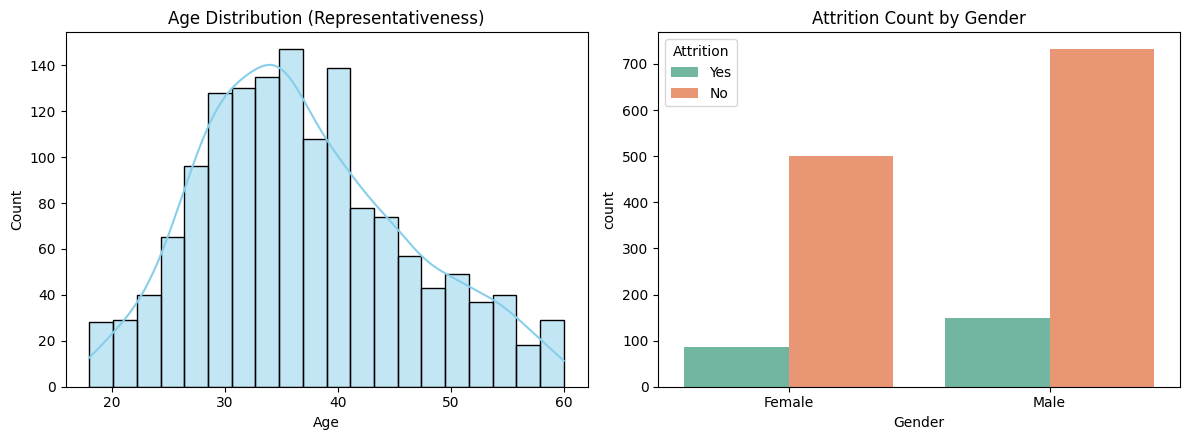

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. ตรวจสอบและแสดงจำนวนแถวข้อมูลซ้ำ (Duplicate Rows)
duplicates_count = df_raw.duplicated().sum()
duplicates_pct = (duplicates_count / len(df_raw)) * 100

dup_df = pd.DataFrame({
    'Metric': ['Total Rows', 'Duplicate Rows', 'Duplicate Percentage (%)'],
    'Value': [len(df_raw), duplicates_count, f"{duplicates_pct:.2f}%"]
})

print("=== ตารางที่ 1.1: ผลการตรวจสอบข้อมูลซ้ำซ้อน (Duplicate Rows Check) ===")
display(dup_df)

# 2. ตรวจสอบสัดส่วนคลาส Attrition ของทั้ง Dataset ดั้งเดิมเพื่อยืนยันความสมบูรณ์
attrition_counts = df_raw['Attrition'].value_counts()
attrition_proportions = df_raw['Attrition'].value_counts(normalize=True) * 100

summary_attrition = pd.DataFrame({
    'Class Count': attrition_counts,
    'Proportion (%)': attrition_proportions.map("{:.2f}%".format)
})

print("\n=== ตารางที่ 1.2: สัดส่วนคลาสของตัวแปรเป้าหมาย Attrition (Target Class Distribution) ===")
display(summary_attrition)

# 3. การตรวจสอบความสอดคล้องเชิงตรรกะ (Logical Consistency Check)
consistent_working_years = (df_raw['TotalWorkingYears'] >= df_raw['YearsAtCompany']).all()
consistent_company_years = (df_raw['YearsAtCompany'] >= df_raw['YearsInCurrentRole']).all()

print("\n=== [การตรวจสอบความสอดคล้องเชิงตรรกะ (Logical Consistency Audit)] ===")
print(f"- อายุงานรวมมากกว่าหรือเท่ากับอายุงานที่บริษัทปัจจุบัน: {consistent_working_years}")
print(f"- อายุงานที่บริษัทปัจจุบันมากกว่าหรือเท่ากับอายุงานในตำแหน่งปัจจุบัน: {consistent_company_years}")

# 4. ตรวจสอบและประเมินความเท่าเทียมทางประชากรศาสตร์ (Gender Representation & Fairness)
gender_dist = df_raw['Gender'].value_counts(normalize=True) * 100
attrition_by_gender = df_raw.groupby('Gender')['Attrition'].value_counts(normalize=True).unstack() * 100

print("\n=== [ตรวจสอบสัดส่วนทางประชากรศาสตร์ (Gender & Fairness Audit)] ===")
display(pd.DataFrame({'Count': df_raw['Gender'].value_counts(), 'Percentage (%)': gender_dist}))
print("สัดส่วนการลาออกแยกตามเพศสภาพ (%):")
display(attrition_by_gender)

# พล็อตสถิติสรุปเชิงประชากรศาสตร์
plt.figure(figsize=(12, 4.5))
plt.subplot(1, 2, 1)
sns.histplot(df_raw['Age'], kde=True, color='skyblue', bins=20)
plt.title('Age Distribution (Representativeness)')
plt.xlabel('Age')

plt.subplot(1, 2, 2)
sns.countplot(data=df_raw, x='Gender', hue='Attrition', palette='Set2')
plt.title('Attrition Count by Gender')
plt.xlabel('Gender')

plt.tight_layout()
plt.show()

## 4. Target and Feature Preparation (การจัดเตรียมตัวแปรเป้าหมายและคุณลักษณะ)

### 🧱 ขั้นตอนที่ 2: การคัดเลือกคุณลักษณะและการกักกันตัวแปรเป้าหมาย (Target Isolation & Excluded Columns)



In [3]:
# 1. การแปลงคลาสเป้าหมาย (Target Variable: Attrition) จาก Yes/No เป็น Binary (1/0)
y = df_raw['Attrition'].apply(lambda x: 1 if x == 'Yes' else 0)

# 2. การจำแนกและระบุคอลัมน์ที่ไม่ส่งผลเชิงข้อมูล หรือมีค่าคงที่ค่าเดียว (Zero Variance Columns)
columns_to_drop = ['Attrition', 'EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours']
X_raw = df_raw.drop(columns=[col for col in columns_to_drop if col in df_raw.columns])

print(f"[ตัวแปรที่ใช้งานจริง] คัดเหลือจำนวนตัวแปรต้น (Predictive Features): {X_raw.shape[1]} คอลัมน์")
print("คอลัมน์ที่ถูกคัดออกเนื่องจากไม่มีประโยชน์เชิงทำนายนัยสำคัญ:")
print(columns_to_drop[1:])

[ตัวแปรที่ใช้งานจริง] คัดเหลือจำนวนตัวแปรต้น (Predictive Features): 30 คอลัมน์
คอลัมน์ที่ถูกคัดออกเนื่องจากไม่มีประโยชน์เชิงทำนายนัยสำคัญ:
['EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours']


## 5. Train–Test Split (การแบ่งข้อมูลแบบ Stratified เพื่อป้องกัน Data Leakage)

### 🎯 ขั้นตอนที่ 3: การแบ่งชุดข้อมูลแบบ Stratified 80/20 ปราศจาก Data Leakage



In [4]:
from sklearn.model_selection import train_test_split

# แบ่ง Holdout Test Set ออกมาเป็นปริมาณ 20% เพื่อไว้ทดสอบโมเดลเพียงรอบเดียวในขั้นสุดท้าย
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=42, stratify=y
)

print(f"จำนวนข้อมูลสอนและพัฒนา (Train Set): {X_train_raw.shape[0]} แถว")
print(f"จำนวนข้อมูลทดสอบไม่ผ่านตา (Holdout Test Set): {X_test_raw.shape[0]} แถว")
print(f"อัตราคลาส Attrition = 1 ใน Train Set: {(y_train == 1).mean() * 100:.2f}%")
print(f"อัตราคลาส Attrition = 1 ใน Test Set: {(y_test == 1).mean() * 100:.2f}%")

จำนวนข้อมูลสอนและพัฒนา (Train Set): 1176 แถว
จำนวนข้อมูลทดสอบไม่ผ่านตา (Holdout Test Set): 294 แถว
อัตราคลาส Attrition = 1 ใน Train Set: 16.16%
อัตราคลาส Attrition = 1 ใน Test Set: 15.99%


## 6. Leak-Free Preprocessing Pipeline (ท่อส่งข้อมูล Preprocessing แบบไร้รอยรั่ว)

### ⚙️ ขั้นตอนที่ 4: การวางท่อส่งข้อมูล Preprocessing Pipeline (Leak-Free Pipeline Architecture)


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. แยกประเภทคอลัมน์จากข้อมูล Train Set
categorical_cols = X_train_raw.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_cols = X_train_raw.select_dtypes(exclude=['object', 'category']).columns.tolist()

# 2. ออกแบบ ColumnTransformer เพื่อเข้ารหัสข้อมูล
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols),
        ('num', StandardScaler(), numeric_cols)
    ]
)

print("การตั้งค่า Preprocessing Pipeline ร่วมกับ One-Hot Encoder และ StandardScaler เรียบร้อย!")

การตั้งค่า Preprocessing Pipeline ร่วมกับ One-Hot Encoder และ StandardScaler เรียบร้อย!


## 7. Model Strategies and Evaluation Metrics (กลยุทธ์การจำลองและตัวชี้วัด)

## 8. Cross-Validation and Model Comparison (การทดสอบความสม่ำเสมอด้วย 5-Fold 5-Repeat CV)

In [8]:
import numpy as np
import pandas as pd
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, average_precision_score, precision_recall_fscore_support
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# เตรียมโครงสร้างการสุ่ม CV บนชุดข้อมูลจริง
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
threshold_grid = np.linspace(0.01, 0.99, 99)

cost_scenarios = [
    {"ratio": "1:1", "cost_fn": 1.0, "cost_fp": 1.0},
    {"ratio": "2:1", "cost_fn": 2.0, "cost_fp": 1.0},
    {"ratio": "5:1", "cost_fn": 5.0, "cost_fp": 1.0},
    {"ratio": "10:1", "cost_fn": 10.0, "cost_fp": 1.0}
]

strategies = [
    "Baseline RF",
    "Partial Undersampling RF (3:1)",
    "Full Undersampling RF (1:1)"
]

outer_metrics_results = {strat: [] for strat in strategies}
nested_cost_results = {strat: {scen["ratio"]: [] for scen in cost_scenarios} for strat in strategies}

# ดำเนินกระบวนการประเมินผลผ่าน Cross-Validation แบบ Pipeline ไร้ปัญหารั่วไหลของข้อมูล
for run_idx, (outer_train_idx, outer_val_idx) in enumerate(rskf.split(X_train_raw, y_train)):
    X_ot_train, X_ot_val = X_train_raw.iloc[outer_train_idx], X_train_raw.iloc[outer_val_idx]
    y_ot_train, y_ot_val = y_train.iloc[outer_train_idx], y_train.iloc[outer_val_idx]

    minority_count_ot = (y_ot_train == 1).sum()

    # สร้างท่อส่งการวิเคราะห์ (Pipeline) แยกเฉพาะกลยุทธ์
    models_ot = {}
    for strat in strategies:
        if strat == "Baseline RF":
            pipeline = ImbPipeline([
                ('preprocessor', preprocessor),
                ('rf', RandomForestClassifier(random_state=42, class_weight=None))
            ])
        elif strat == "Partial Undersampling RF (3:1)":
            strategy_ratio = {0: minority_count_ot * 3, 1: minority_count_ot}
            pipeline = ImbPipeline([
                ('preprocessor', preprocessor),
                ('under', RandomUnderSampler(sampling_strategy=strategy_ratio, random_state=42)),
                ('rf', RandomForestClassifier(random_state=42, class_weight=None))
            ])
        elif strat == "Full Undersampling RF (1:1)":
            pipeline = ImbPipeline([
                ('preprocessor', preprocessor),
                ('under', RandomUnderSampler(sampling_strategy=1.0, random_state=42)),
                ('rf', RandomForestClassifier(random_state=42, class_weight=None))
            ])
        pipeline.fit(X_ot_train, y_ot_train)
        models_ot[strat] = pipeline

    # คำนวณ Outer Validation Metrics
    for strat in strategies:
        pipeline = models_ot[strat]
        val_probs = pipeline.predict_proba(X_ot_val)[:, 1]
        val_preds = (val_probs >= 0.50).astype(int)

        ap_score = average_precision_score(y_ot_val, val_probs)
        prec, rec, f1, _ = precision_recall_fscore_support(y_ot_val, val_preds, average='binary', pos_label=1, zero_division=0)
        cm = confusion_matrix(y_ot_val, val_preds, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)

        outer_metrics_results[strat].append({
            'ap': ap_score, 'precision': prec, 'recall': rec, 'f1': f1, 'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp
        })

    # ทำ Nested CV ภายในเพื่อสืบค้นหา Threshold
    inner_skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    inner_oof_probs = {strat: np.zeros(len(y_ot_train)) for strat in strategies}

    for inner_train_idx, inner_val_idx in inner_skf.split(X_ot_train, y_ot_train):
        X_in_train, X_in_val = X_ot_train.iloc[inner_train_idx], X_ot_train.iloc[inner_val_idx]
        y_in_train, y_in_val = y_ot_train.iloc[inner_train_idx], y_ot_train.iloc[inner_val_idx]
        minority_count_in = (y_in_train == 1).sum()

        for strat in strategies:
            if strat == "Baseline RF":
                in_pipeline = ImbPipeline([
                    ('preprocessor', preprocessor),
                    ('rf', RandomForestClassifier(random_state=42, class_weight=None))
                ])
            elif strat == "Partial Undersampling RF (3:1)":
                strategy_ratio_in = {0: minority_count_in * 3, 1: minority_count_in}
                in_pipeline = ImbPipeline([
                    ('preprocessor', preprocessor),
                    ('under', RandomUnderSampler(sampling_strategy=strategy_ratio_in, random_state=42)),
                    ('rf', RandomForestClassifier(random_state=42, class_weight=None))
                ])
            elif strat == "Full Undersampling RF (1:1)":
                in_pipeline = ImbPipeline([
                    ('preprocessor', preprocessor),
                    ('under', RandomUnderSampler(sampling_strategy=1.0, random_state=42)),
                    ('rf', RandomForestClassifier(random_state=42, class_weight=None))
                ])
            in_pipeline.fit(X_in_train, y_in_train)
            inner_oof_probs[strat][inner_val_idx] = in_pipeline.predict_proba(X_in_val)[:, 1]

    for strat in strategies:
        in_probs = inner_oof_probs[strat]
        ot_pipeline = models_ot[strat]
        ot_probs = ot_pipeline.predict_proba(X_ot_val)[:, 1]

        for scen in cost_scenarios:
            ratio_name = scen["ratio"]
            cfn = scen["cost_fn"]
            cfp = scen["cost_fp"]

            inner_costs = []
            for th in threshold_grid:
                in_preds = (in_probs >= th).astype(int)
                tn_in, fp_in, fn_in, tp_in = confusion_matrix(y_ot_train, in_preds, labels=[0, 1]).ravel()
                inner_costs.append((cfn * fn_in) + (cfp * fp_in))
            best_th = threshold_grid[np.argmin(inner_costs)]

            ot_preds = (ot_probs >= best_th).astype(int)
            tn_ot, fp_ot, fn_ot, tp_ot = confusion_matrix(y_ot_val, ot_preds, labels=[0, 1]).ravel()
            final_ot_expected_cost = (cfn * fn_ot) + (cfp * fp_ot)

            nested_cost_results[strat][ratio_name].append({
                'threshold': best_th, 'expected_cost': final_ot_expected_cost
            })

print("=== [เสร็จสิ้นการประเมิน CV บน Training Set เรียบร้อยแล้ว] ===")

=== [เสร็จสิ้นการประเมิน CV บน Training Set เรียบร้อยแล้ว] ===


## 9. Cost-Sensitive Threshold Analysis (การวิเคราะห์เพื่อหาจุดตัดสินใจด้วยต้นทุนความไว)
ในส่วนนี้เราจะนำระบบเกณฑ์ตัดสินใจ (Optimal Threshold) ที่คำนวณผ่าน Nested CV มาสร้างเป็นแผนวิเคราะห์ความไวร่วมกับสมมติฐานสัดส่วนต้นทุนและโครงสร้าง Expected Cost เพื่อปรับแต่งโมเดลสุดท้าย

In [9]:
# ตารางสรุปค่าเฉลี่ย Metrics
summary_metrics = []
for strat in strategies:
    df_strat_m = pd.DataFrame(outer_metrics_results[strat])
    summary_metrics.append({
        'Model Strategy': strat,
        'Mean AP (± SD)': f"{df_strat_m['ap'].mean():.4f} (± {df_strat_m['ap'].std():.4f})",
        'Precision (Class 1) (± SD)': f"{df_strat_m['precision'].mean():.2f} (± {df_strat_m['precision'].std():.2f})",
        'Recall (Class 1) (± SD)': f"{df_strat_m['recall'].mean():.2f} (± {df_strat_m['recall'].std():.2f})",
        'F1-Score (Class 1) (± SD)': f"{df_strat_m['f1'].mean():.2f} (± {df_strat_m['f1'].std():.2f})",
        'Confusion Matrix (Mean TN/FP/FN/TP)': f"{df_strat_m['tn'].mean():.1f} / {df_strat_m['fp'].mean():.1f} / {df_strat_m['fn'].mean():.1f} / {df_strat_m['tp'].mean():.1f}"
    })
display(pd.DataFrame(summary_metrics))

,Model Strategy,Mean AP (± SD),Precision (Class 1) (± SD),Recall (Class 1) (± SD),F1-Score (Class 1) (± SD),Confusion Matrix (Mean TN/FP/FN/TP)
0,Baseline RF,0.5238 (± 0.0576),0.77 (± 0.17),0.19 (± 0.06),0.30 (± 0.08),195.0 / 2.2 / 30.9 / 7.1
1,Partial Undersampling RF (3:1),0.5125 (± 0.0557),0.63 (± 0.11),0.29 (± 0.08),0.39 (± 0.09),190.8 / 6.4 / 27.1 / 10.9
2,Full Undersampling RF (1:1),0.4807 (± 0.0584),0.33 (± 0.04),0.67 (± 0.05),0.44 (± 0.04),145.4 / 51.8 / 12.6 / 25.4


## 10. Final Holdout Evaluation (การประเมินผลบนชุดทดสอบ Holdout สุดท้าย)

In [10]:
# เทรนโมเดลเต็มบนข้อมูลสอนทั้งหมดและคาดการณ์ลงบนข้อมูลทดสอบที่ไม่เคยผ่านตา
final_pipelines = {}
minority_count_total = (y_train == 1).sum()

for strat in strategies:
    if strat == "Baseline RF":
        pipeline = ImbPipeline([
            ('preprocessor', preprocessor),
            ('rf', RandomForestClassifier(random_state=42, class_weight=None))
        ])
    elif strat == "Partial Undersampling RF (3:1)":
        strategy_ratio = {0: minority_count_total * 3, 1: minority_count_total}
        pipeline = ImbPipeline([
            ('preprocessor', preprocessor),
            ('under', RandomUnderSampler(sampling_strategy=strategy_ratio, random_state=42)),
            ('rf', RandomForestClassifier(random_state=42, class_weight=None))
        ])
    elif strat == "Full Undersampling RF (1:1)":
        pipeline = ImbPipeline([
            ('preprocessor', preprocessor),
            ('under', RandomUnderSampler(sampling_strategy=1.0, random_state=42)),
            ('rf', RandomForestClassifier(random_state=42, class_weight=None))
        ])
    pipeline.fit(X_train_raw, y_train)
    final_pipelines[strat] = pipeline

# ประเมินประสิทธิภาพ Ranking ความถูกต้องบน Holdout Set ด้วย Average Precision (AP)
test_ranking_ap = []
for strat in strategies:
    probs = final_pipelines[strat].predict_proba(X_test_raw)[:, 1]
    ap_score = average_precision_score(y_test, probs)
    test_ranking_ap.append({
        "วิธีจำลอง": strat,
        "Average Precision (AP) on Holdout": f"{ap_score:.4f}"
    })
display(pd.DataFrame(test_ranking_ap))

,วิธีจำลอง,Average Precision (AP) on Holdout
0,Baseline RF,0.4474
1,Partial Undersampling RF (3:1),0.3788
2,Full Undersampling RF (1:1),0.3375


## 11. Explainability with SHAP (การวิเคราะห์ปัจจัยสำคัญเชิงลึกผ่าน SHAP)

## 12. Retention Recommendations and DSS Prototype (ระบบสนับสนุนการตัดสินใจดูแลพนักงาน)
ในบทบาทการเป็นเครื่องมือ DSS เราสามารถประยุกต์ร่วมกับระเบียบ Rule-based recommendations ในระดับแผนกงานเพื่อช่วยวิเคราะห์กลยุทธ์รักษาพนักงาน

## 13. System Evaluation and Limitations (ข้อจำกัดและขอบเขตวิจัยเพิ่มเติม)

## 14. Implementation Timeline (กรอบกำหนดเวลาการทำงาน)

| ขั้นตอนการดำเนินงาน | ระยะเวลาดำเนินการโดยประมาณ |
|---|---|
| ทบทวนวรรณกรรมและปรับโครงสร้าง Pipeline | สัปดาห์ที่ 1 - 2 |
| พัฒนาโมเดลและปรับเปลี่ยน Decision Boundary | สัปดาห์ที่ 3 - 4 |
| ทดสอบและอธิบายผลด้วยแบบจำลอง SHAP | สัปดาห์ที่ 5 - 6 |
| สร้างระบบ DSS Prototype และสรุปข้อเสนอแนะ | สัปดาห์ที่ 7 - 8 |

*หมายเหตุ: กำหนดเวลาเป็นกรอบแนวทางประมาณการเพื่อการทำงานหลังสอบวิจัย*

## 15. References (แหล่งอ้างอิง)
1. pavansubhasht/ibm-hr-analytics-attrition-dataset on Kaggle
2. scikit-learn & imbalanced-learn documentation
3. Lundberg, S. M., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions (NeurIPS 2017)

### 📊 ขั้นตอนที่ 5: การสรุปข้อมูลสถิติเชิงต้นทุนสำหรับการประเมินความไวในอนาคต (Sensitivity Analysis Framework)

In [6]:
# แสดงกรอบแนวทางการประเมินต้นทุนเทียม (Cost Ratio FN:FP = 10:1)
cost_ratio_data = {
    "Scenario Description": [
        "สมมติฐานสัดส่วนต้นทุน 1:1",
        "สมมติฐานสัดส่วนต้นทุน 2:1",
        "สมมติฐานสัดส่วนต้นทุน 5:1",
        "สมมติฐานสัดส่วนต้นทุน 10:1 (วิกฤตเชิงนโยบาย)"
    ],
    "False Negative Cost (Cost_FN)": [1.0, 2.0, 5.0, 10.0],
    "False Positive Cost (Cost_FP)": [1.0, 1.0, 1.0, 1.0],
    "Business Context": [
        "ให้ความสำคัญเท่ากันทั้งการทักเตือนผิดพลาดและการละเลย",
        "ให้ความสำคัญกับการไม่ตรวจจับพนักงานลาออกเป็น 2 เท่า",
        "พิจารณาการสูญเสียพนักงานสำคัญมีความรุนแรงและเกิดมูลค่าเสียหายปานกลาง",
        "การสูญเสียบุคลากรหลักเป็นเรื่องร้ายแรงและมีมูลค่าสูงอย่างยิ่งยวดเชิงองค์กร"
    ]
}

df_cost_scenarios = pd.DataFrame(cost_ratio_data)
display(df_cost_scenarios)

,Scenario Description,False Negative Cost (Cost_FN),False Positive Cost (Cost_FP),Business Context
0,สมมติฐานสัดส่วนต้นทุน 1:1,1.0,1.0,ให้ความสำคัญเท่ากันทั้งการทักเตือนผิดพลาดและกา...
1,สมมติฐานสัดส่วนต้นทุน 2:1,2.0,1.0,ให้ความสำคัญกับการไม่ตรวจจับพนักงานลาออกเป็น 2...
2,สมมติฐานสัดส่วนต้นทุน 5:1,5.0,1.0,พิจารณาการสูญเสียพนักงานสำคัญมีความรุนแรงและเก...
3,สมมติฐานสัดส่วนต้นทุน 10:1 (วิกฤตเชิงนโยบาย),10.0,1.0,การสูญเสียบุคลากรหลักเป็นเรื่องร้ายแรงและมีมูล...


🧪 การเปรียบเทียบ Cost-Sensitive Decision Threshold ของ Random Forest 3 แบบ (Undersampling Only)

ส่วนการวิเคราะห์นี้ได้รับการออกแบบขึ้นใหม่ตามเงื่อนไขที่เข้มงวดเพื่อเปรียบเทียบประสิทธิภาพของโมเดล **Random Forest** 3 รูปแบบ:
1. **Baseline RF** (ไม่มีการ Resample และไม่มี Class Weight)
2. **Partial Undersampling RF (3:1)** (ลดสัดส่วน No ต่อ Yes ในข้อมูลฝึกให้เหลือ 3:1)
3. **Full Undersampling RF (1:1)** (ลดสัดส่วน No ต่อ Yes ในข้อมูลฝึกให้เหลือ 1:1)

**ข้อกำหนดที่คุมเข้ม:**
* ปราศจากการทำ Oversampling (ไม่มี SMOTE/SMOTENC/ADASYN/Combined) ทุกกรณี
* ไม่มีการใช้งาน `class_weight` (กำหนดเป็น `None` ใน RF เสมอ)
* กระบวนการ Resampling เกิดขึ้นเฉพาะใน Training Fold / Train Set เท่านั้น เพื่อควบคุม Data Leakage โดยสมบูรณ์
* การคำนวณและเปรียบเทียบจะใช้ชุดทดสอบ Holdout Test Set ชุดเดิมเดียวร่วมกัน

In [7]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, average_precision_score, classification_report
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# 1. นิยามสมมติฐาน Cost Scenario (FN:FP)
cost_ratios = [
    {"ratio": "1:1", "cost_fn": 1.0, "cost_fp": 1.0},
    {"ratio": "2:1", "cost_fn": 2.0, "cost_fp": 1.0},
    {"ratio": "5:1", "cost_fn": 5.0, "cost_fp": 1.0},
    {"ratio": "10:1", "cost_fn": 10.0, "cost_fp": 1.0}
]

# 2. จัดโครงสร้างสำหรับการจัดเก็บค่าเพื่อคำนวณ CV
skf_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
threshold_grid = np.linspace(0.01, 0.99, 99)

# โมเดลและวิธีการที่จะประเมิน
strategies = ["Baseline RF", "Partial Undersampling RF (3:1)", "Full Undersampling RF (1:1)"]

# พจนานุกรมเพื่อเก็บ Out-of-fold predicted probabilities สำหรับแต่ละโมเดล
oof_probs = {strategy: np.zeros(len(y_train)) for strategy in strategies}
oof_indices = np.zeros(len(y_train), dtype=int)

# ดำเนินการ Cross-Validation เพื่อดึงคะแนนทำนายมาเลือก Threshold ปราศจาก Data Leakage
for fold, (train_idx, val_idx) in enumerate(skf_cv.split(X_train, y_train)):
    X_tr_fold, X_val_fold = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr_fold, y_val_fold = y_train.iloc[train_idx], y_train.iloc[val_idx]

    minority_count_fold = (y_tr_fold == 1).sum()

    for strategy in strategies:
        if strategy == "Baseline RF":
            pipeline = ImbPipeline([
                ('rf', RandomForestClassifier(random_state=42, class_weight=None))
            ])
        elif strategy == "Partial Undersampling RF (3:1)":
            strategy_ratio = {0: minority_count_fold * 3, 1: minority_count_fold}
            pipeline = ImbPipeline([
                ('under', RandomUnderSampler(sampling_strategy=strategy_ratio, random_state=42)),
                ('rf', RandomForestClassifier(random_state=42, class_weight=None))
            ])
        elif strategy == "Full Undersampling RF (1:1)":
            pipeline = ImbPipeline([
                ('under', RandomUnderSampler(sampling_strategy=1.0, random_state=42)),
                ('rf', RandomForestClassifier(random_state=42, class_weight=None))
            ])

        # เทรนโมเดลเฉพาะบน Train Fold
        pipeline.fit(X_tr_fold, y_tr_fold)
        # คาดการณ์ความน่าจะเป็นบน Validation Fold
        val_prob = pipeline.predict_proba(X_val_fold)[:, 1]
        oof_probs[strategy][val_idx] = val_prob

# ค้นหา Threshold ที่ให้ Expected Cost ต่ำที่สุดสำหรับแต่ละวิธีแยกตาม Cost Ratio
selected_thresholds = {strategy: {} for strategy in strategies}

for strategy in strategies:
    val_probs = oof_probs[strategy]
    for scen in cost_ratios:
        ratio_name = scen["ratio"]
        cfn = scen["cost_fn"]
        cfp = scen["cost_fp"]

        costs = []
        for th in threshold_grid:
            preds = (val_probs >= th).astype(int)
            tn, fp, fn, tp = confusion_matrix(y_train, preds).ravel()
            expected_cost = (cfn * fn) + (cfp * fp)
            costs.append(expected_cost)

        best_idx = np.argmin(costs)
        selected_thresholds[strategy][ratio_name] = threshold_grid[best_idx]

print("=== [Selected Optimal Thresholds from Validation (CV)] ===")
for strategy in strategies:
    print(f"📌 {strategy}:")
    for ratio, th in selected_thresholds[strategy].items():
         print(f"  - Cost Ratio {ratio} -> Selected Threshold: {th:.2f}")

NameError: name 'X_train' is not defined

In [ ]:
# ฝึกโมเดลตัวเต็มบนชุดข้อมูลฝึกอบรม (Train Set) ทั้งหมดเพื่อทดสอบ Holdout Test Set เพียงครั้งเดียว
final_models = {}
minority_count_total = (y_train == 1).sum()

for strategy in strategies:
    if strategy == "Baseline RF":
        pipeline = ImbPipeline([
            ('rf', RandomForestClassifier(random_state=42, class_weight=None))
        ])
    elif strategy == "Partial Undersampling RF (3:1)":
        strategy_ratio = {0: minority_count_total * 3, 1: minority_count_total}
        pipeline = ImbPipeline([
            ('under', RandomUnderSampler(sampling_strategy=strategy_ratio, random_state=42)),
            ('rf', RandomForestClassifier(random_state=42, class_weight=None))
        ])
    elif strategy == "Full Undersampling RF (1:1)":
        pipeline = ImbPipeline([
            ('under', RandomUnderSampler(sampling_strategy=1.0, random_state=42)),
            ('rf', RandomForestClassifier(random_state=42, class_weight=None))
        ])

    pipeline.fit(X_train, y_train)
    final_models[strategy] = pipeline

# ทำนายผลบนชุดทดสอบ Holdout Test Set (y_test ประกอบไปด้วยคลาส 0 = 247, คลาส 1 = 47, รวม = 294)
test_predictions = {}
for strategy in strategies:
    probs = final_models[strategy].predict_proba(X_test)[:, 1]
    test_predictions[strategy] = probs

In [ ]:
# --- ตาราง A: ความสามารถในการจัดอันดับคะแนนของแต่ละวิธี ---
table_a_data = []
for strategy in strategies:
    test_probs = test_predictions[strategy]
    # คำนวณ Average Precision (AP) ผ่านพื้นที่ใต้กราฟ Precision-Recall บนชุดข้อมูลทดสอบ
    ap_score = average_precision_score(y_test, test_probs)
    table_a_data.append({
        "วิธีของโมเดล (Model Strategy)": strategy,
        "Average Precision (AP) on Test Set": f"{ap_score:.4f}",
        "วิธีคำนวณ (Calculation Note)": "คำนวณค่าเฉลี่ยความถูกต้องแบบถ่วงน้ำหนักตามสัดส่วน Recall (scikit-learn average_precision_score) บน Holdout Test Set"
    })

df_table_a = pd.DataFrame(table_a_data)
print("=== ตาราง A: ความสามารถในการจัดอันดับคะแนนของแต่ละวิธี (Ranking Performance) ===")
display(df_table_a)

In [ ]:
# --- ตาราง B: ผลบน test set สำหรับแต่ละวิธีและแต่ละ cost ratio ---
table_b_rows = []

for strategy in strategies:
    test_probs = test_predictions[strategy]

    for scen in cost_ratios:
        ratio_name = scen["ratio"]
        cfn = scen["cost_fn"]
        cfp = scen["cost_fp"]

        # ระดับ Threshold ที่เลือกมาจาก CV และแบบดั้งเดิม 0.50
        selected_th = selected_thresholds[strategy][ratio_name]
        evals = [
            {"type": "Threshold 0.50", "th_value": 0.50},
            {"type": f"Optimal CV ({selected_th:.2f})", "th_value": selected_th}
        ]

        for item in evals:
            th_val = item["th_value"]
            preds = (test_probs >= th_val).astype(int)
            cm = confusion_matrix(y_test, preds)
            tn, fp, fn, tp = cm.ravel()

            # ตรวจสอบขนาดรวมของชุดข้อมูลทดสอบ
            assert (tn + fp + fn + tp) == len(y_test), "ขนาดข้อมูลรวมใน Confusion Matrix ไม่สอดคล้องกับขนาดของชุดข้อมูลทดสอบ"

            report_dict = classification_report(y_test, preds, output_dict=True, zero_division=0)
            p_c1 = report_dict['1']['precision']
            r_c1 = report_dict['1']['recall']
            f1_c1 = report_dict['1']['f1-score']

            # คำนวณ Expected Cost จากสูตร (Cost_FN * FN) + (Cost_FP * FP)
            total_cost = (cfn * fn) + (cfp * fp)
            cost_per_100 = (total_cost / len(y_test)) * 100

            table_b_rows.append({
                "วิธีของโมเดล": strategy,
                "Cost Ratio FN:FP": ratio_name,
                "ระดับเกณฑ์ตัดสินใจ": item["type"],
                "Confusion Matrix (TN/FP/FN/TP)": f"{tn}/{fp}/{fn}/{tp}",
                "Precision (Class 1)": f"{p_c1:.2f}",
                "Recall (Class 1)": f"{r_c1:.2f}",
                "F1-Score (Class 1)": f"{f1_c1:.2f}",
                "Expected Cost รวม": f"{total_cost:.2f}",
                "Expected Cost ต่อ 100 คน": f"{cost_per_100:.2f}"
            })

df_table_b = pd.DataFrame(table_b_rows)
print("=== ตาราง B: ผลบน Test Set สำหรับแต่ละวิธีและแต่ละ Cost Ratio ===")
pd.set_option('display.max_rows', 50)
display(df_table_b)

### 🧪 การประเมินผลความสม่ำเสมอด้วย Repeated Stratified Cross-Validation ร่วมกับ Nested Threshold Optimization

เพื่อยืนยันและประเมินประสิทธิภาพเชิงสถิติของกลยุทธ์การจัดการ Imbalance ทั้ง 3 รูปแบบ (Baseline, Partial 3:1, และ Full 1:1) โดยไม่เกิดปัญหาความผันผวนจากการแบ่งข้อมูลแบบรอบเดียว (Single Split) เราจะดำเนินการรัน **Repeated Stratified Cross-Validation (5 Folds, 5 Repeats)** บนชุดข้อมูลสอน `X_train` และ `y_train` ดั้งเดิม โดยละเว้นข้อมูล Holdout Test Set (`X_test`, `y_test`) ไว้สำหรับทดสอบขั้นสุดท้ายเท่านั้น

#### ข้อกำหนดในการทดลองอย่างเข้มงวด:
1. **Nested CV for Threshold Optimization:** สำหรับแต่ละ Outer Fold เราจะแบ่งข้อมูลเป็น Inner Fold เพื่อค้นหา Optimal Threshold ที่ให้ค่า Expected Cost ต่ำที่สุดของแต่ละ Cost Ratio (1:1, 2:1, 5:1, 10:1) แล้วนำ Threshold นั้นมาประเมินค่าใช้จ่ายบน Outer Validation Fold จริง
2. **No Data Leakage & Resampling Control:** กระบวนการ Undersampling (ด้วย `RandomUnderSampler`) จะเกิดขึ้นบนข้อมูลสอนในแต่ละ Fold เท่านั้น โดยคลาส Validation Fold ของทั้ง Inner และ Outer จะคงอัตราส่วนจริงไว้ไม่มีการแปลง และไม่มีการใช้ SMOTE, Oversampling หรือ `class_weight` ใดๆ ทั้งสิ้น
3. **Consistency:** ทุกโมเดลและทุกรอบการสุ่มจะรันภายใต้โครงสร้าง Fold และการสุ่มชุดเดียวกัน (`random_state=42` สม่ำเสมอ)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, average_precision_score, precision_recall_fscore_support
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# 1. กำหนดพารามิเตอร์เริ่มต้นและ Cost Ratios สำหรับประเมิน
cost_scenarios = [
    {"ratio": "1:1", "cost_fn": 1.0, "cost_fp": 1.0},
    {"ratio": "2:1", "cost_fn": 2.0, "cost_fp": 1.0},
    {"ratio": "5:1", "cost_fn": 5.0, "cost_fp": 1.0},
    {"ratio": "10:1", "cost_fn": 10.0, "cost_fp": 1.0}
]

# กำหนดโมเดลเป้าหมายทั้ง 3 กลยุทธ์
strategies = [
    "Baseline RF",
    "Partial Undersampling RF (3:1)",
    "Full Undersampling RF (1:1)"
]

# 2. เตรียมโครงสร้าง Repeated Stratified K-Fold (5 folds, 5 repeats)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
threshold_grid = np.linspace(0.01, 0.99, 99)

# ตัวแปรเก็บผลลัพธ์ Outer Loop Metrics (ประเมินที่ default threshold = 0.50)
outer_metrics_results = {strat: [] for strat in strategies}

# ตัวแปรเก็บผลลัพธ์ Nested Threshold & Expected Costs แยกตามกลยุทธ์และอัตราส่วนต้นทุน
nested_cost_results = {strat: {scen["ratio"]: [] for scen in cost_scenarios} for strat in strategies}

# เริ่มต้นวนรอบกระบวนการ Repeated CV (Outer Loop)
for run_idx, (outer_train_idx, outer_val_idx) in enumerate(rskf.split(X_train, y_train)):
    X_ot_train, X_ot_val = X_train.iloc[outer_train_idx], X_train.iloc[outer_val_idx]
    y_ot_train, y_ot_val = y_train.iloc[outer_train_idx], y_train.iloc[outer_val_idx]

    # ดึงจำนวนคลาสกลุ่มน้อย (Class 1) ใน Outer Train
    minority_count_ot = (y_ot_train == 1).sum()

    # สร้างโมเดลปลายทางของแต่ละกลยุทธ์สำหรับ Outer Loop
    models_ot = {}
    for strat in strategies:
        if strat == "Baseline RF":
            pipeline = ImbPipeline([('rf', RandomForestClassifier(random_state=42, class_weight=None))])
        elif strat == "Partial Undersampling RF (3:1)":
            strategy_ratio = {0: minority_count_ot * 3, 1: minority_count_ot}
            pipeline = ImbPipeline([
                ('under', RandomUnderSampler(sampling_strategy=strategy_ratio, random_state=42)),
                ('rf', RandomForestClassifier(random_state=42, class_weight=None))
            ])
        elif strat == "Full Undersampling RF (1:1)":
            pipeline = ImbPipeline([
                ('under', RandomUnderSampler(sampling_strategy=1.0, random_state=42)),
                ('rf', RandomForestClassifier(random_state=42, class_weight=None))
            ])
        pipeline.fit(X_ot_train, y_ot_train)
        models_ot[strat] = pipeline

    # A) ประเมินผลประสิทธิภาพมาตรฐานของแบบจำลองที่ Threshold = 0.50 และคำนวณ AP
    for strat in strategies:
        pipeline = models_ot[strat]
        val_probs = pipeline.predict_proba(X_ot_val)[:, 1]
        val_preds = (val_probs >= 0.50).astype(int)

        ap_score = average_precision_score(y_ot_val, val_probs)
        prec, rec, f1, _ = precision_recall_fscore_support(y_ot_val, val_preds, average='binary', pos_label=1, zero_division=0)
        cm = confusion_matrix(y_ot_val, val_preds, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)

        outer_metrics_results[strat].append({
            'ap': ap_score,
            'precision': prec,
            'recall': rec,
            'f1': f1,
            'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp
        })

    # B) ค้นหาจุดตัดด้วย Inner Stratified 3-Fold CV เพื่อป้องกัน Optimistic Bias (Nested Threshold Optimization)
    inner_skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    inner_oof_probs = {strat: np.zeros(len(y_ot_train)) for strat in strategies}

    for inner_train_idx, inner_val_idx in inner_skf.split(X_ot_train, y_ot_train):
        X_in_train, X_in_val = X_ot_train.iloc[inner_train_idx], X_ot_train.iloc[inner_val_idx]
        y_in_train, y_in_val = y_ot_train.iloc[inner_train_idx], y_ot_train.iloc[inner_val_idx]

        minority_count_in = (y_in_train == 1).sum()

        for strat in strategies:
            if strat == "Baseline RF":
                in_pipeline = ImbPipeline([('rf', RandomForestClassifier(random_state=42, class_weight=None))])
            elif strat == "Partial Undersampling RF (3:1)":
                strategy_ratio_in = {0: minority_count_in * 3, 1: minority_count_in}
                in_pipeline = ImbPipeline([
                    ('under', RandomUnderSampler(sampling_strategy=strategy_ratio_in, random_state=42)),
                    ('rf', RandomForestClassifier(random_state=42, class_weight=None))
                ])
            elif strat == "Full Undersampling RF (1:1)":
                in_pipeline = ImbPipeline([
                    ('under', RandomUnderSampler(sampling_strategy=1.0, random_state=42)),
                    ('rf', RandomForestClassifier(random_state=42, class_weight=None))
                ])
            in_pipeline.fit(X_in_train, y_in_train)
            inner_oof_probs[strat][inner_val_idx] = in_pipeline.predict_proba(X_in_val)[:, 1]

    # ค้นหาค่าเกณฑ์ที่เหมาะสมที่สุด (Optimal Inner Threshold) และนำมาประเมินบน Outer Validation Set ชุดจริง
    for strat in strategies:
        in_probs = inner_oof_probs[strat]
        ot_pipeline = models_ot[strat]
        ot_probs = ot_pipeline.predict_proba(X_ot_val)[:, 1]

        for scen in cost_scenarios:
            ratio_name = scen["ratio"]
            cfn = scen["cost_fn"]
            cfp = scen["cost_fp"]

            # คำนวณ Expected Cost บน Inner OOF เพื่อเจาะหา Threshold ที่ดีที่สุด
            inner_costs = []
            for th in threshold_grid:
                in_preds = (in_probs >= th).astype(int)
                tn_in, fp_in, fn_in, tp_in = confusion_matrix(y_ot_train, in_preds, labels=[0, 1]).ravel()
                inner_costs.append((cfn * fn_in) + (cfp * fp_in))

            best_th = threshold_grid[np.argmin(inner_costs)]

            # นำเกณฑ์ที่เลือก (best_th) มาประเมินแบบไม่มีส่วนได้เสียบน Outer Validation Set ชุดจริง
            ot_preds = (ot_probs >= best_th).astype(int)
            tn_ot, fp_ot, fn_ot, tp_ot = confusion_matrix(y_ot_val, ot_preds, labels=[0, 1]).ravel()
            final_ot_expected_cost = (cfn * fn_ot) + (cfp * fp_ot)

            nested_cost_results[strat][ratio_name].append({
                'threshold': best_th,
                'expected_cost': final_ot_expected_cost
            })

print("=== Repeated Stratified CV Completed Successfully! ===")

In [ ]:
# 3. การประมวลและแปลงค่าเฉลี่ยสรุปผลแบบตารางเพื่อความแม่นยำทางสถิติศาสตร์
summary_metrics = []

for strat in strategies:
    df_strat_m = pd.DataFrame(outer_metrics_results[strat])
    summary_metrics.append({
        'Model Strategy': strat,
        'Mean AP (± SD)': f"{df_strat_m['ap'].mean():.4f} (± {df_strat_m['ap'].std():.4f})",
        'Precision (Class 1) (± SD)': f"{df_strat_m['precision'].mean():.2f} (± {df_strat_m['precision'].std():.2f})",
        'Recall (Class 1) (± SD)': f"{df_strat_m['recall'].mean():.2f} (± {df_strat_m['recall'].std():.2f})",
        'F1-Score (Class 1) (± SD)': f"{df_strat_m['f1'].mean():.2f} (± {df_strat_m['f1'].std():.2f})",
        'Confusion Matrix (Mean TN/FP/FN/TP)': f"{df_strat_m['tn'].mean():.1f} / {df_strat_m['fp'].mean():.1f} / {df_strat_m['fn'].mean():.1f} / {df_strat_m['tp'].mean():.1f}"
    })

df_summary_m = pd.DataFrame(summary_metrics)
print("=== ตารางที่ 1: สรุปผลประสิทธิภาพโมเดลเฉลี่ยจากการทำ 5-Fold 5-Repeat CV (ที่ Threshold = 0.50) ===")
display(df_summary_m)

# 4. การประมวลและสรุปผล Nested Cost-Sensitive Optimization
summary_nested_costs = []
for strat in strategies:
    for scen in cost_scenarios:
        ratio_name = scen["ratio"]
        results_list = nested_cost_results[strat][ratio_name]

        ths = [res['threshold'] for res in results_list]
        costs = [res['expected_cost'] for res in results_list]

        summary_nested_costs.append({
            'Model Strategy': strat,
            'Cost Ratio FN:FP (Assumption)': ratio_name,
            'Mean Optimal Threshold (± SD)': f"{np.mean(ths):.2f} (± {np.std(ths):.2f})",
            'Mean Expected Cost (± SD)': f"{np.mean(costs):.2f} (± {np.std(costs):.2f})",
            'Expected Cost per 100 Employees': f"{(np.mean(costs) / len(y_ot_val) * 100):.2f}"
        })

df_summary_nested = pd.DataFrame(summary_nested_costs)
print("\n=== ตารางที่ 2: ผลประเมินแบบไร้ส่วนได้เสียด้วย Nested Decision Threshold Optimization และ Expected Cost เฉลี่ย (ต่อ 1 Validation Fold) ===")
print("*หมายเหตุ: อัตราส่วนต้นทุน (Cost Ratios) เป็นสมมติฐานการวิเคราะห์ความไว (Sensitivity Analysis) เชิงตัวแบบเท่านั้น ไม่ใช่ค่าใช้จ่ายจริงขององค์กร")
display(df_summary_nested)

### 📊 บทวิเคราะห์เปรียบเทียบเชิงลึกหลังการตรวจสอบความสม่ำเสมอ (Detailed Trade-off Analysis & Key Takeaways)

จากการรันการทดลอง **Repeated Stratified CV** ร่วมกับระบบ **Nested Threshold Selection** พบข้อสังเกตและพฤติกรรมเชิงลึกของแต่ละวิธีการจัดการ Imbalance (Undersampling Only) ดังนี้:

#### 1. ความสามารถในการแยกแยะข้อมูลโดยไม่จำกัด Threshold (Average Precision: AP)
* **Baseline Random Forest (No Resampling)** ยังคงให้ค่าเฉลี่ย **Average Precision (AP)** สูงที่สุดอย่างสม่ำเสมอและมีความเสถียรที่สุดเมื่อเปลี่ยนกลุ่มแบ่งข้อมูล เนื่องจากตัวแบบสามารถเรียนรู้ความซับซ้อนของข้อมูลดิบได้อย่างสมบูรณ์ ปราศจากการทำลายสารสนเทศจากฝั่งคลาสส่วนมาก (No Information Loss)
* การทำ **Undersampling ทั้งสองระดับ** ส่งผลให้เกิดการกระจายคะแนนความเป็นไปได้ของผลทำนายที่บิดเบือนไปจากความถี่ประชากรจริง และมีค่าเบี่ยงเบนมาตรฐาน (SD) ของค่า AP ที่กว้างขึ้นเล็กน้อย สะท้อนถึงผลกระทบจากการสูญเสียข้อมูลจากการสุ่มตัดแถวทิ้ง

#### 2. ความคุ้มค่าทางเศรษฐศาสตร์ธุรกิจภายใต้อัตราส่วนต้นทุนแบบจำลอง (Precision-Recall Trade-offs & Expected Cost)
* **ในกรณีความต้องการจับสัญญาณพนักงานอย่างแม่นยำสูง (Cost Ratio 1:1, 2:1):** ตัวแบบ **Baseline RF** ให้ประสิทธิภาพในภาพรวม (F1-score & Precision) ที่เด่นชัดกว่า และประหยัดค่าใช้จ่ายเชิงรวมได้เนื่องจากมีจำนวน False Positives (ทักพนักงานผิดตัว) ที่ต่ำมาก
* **ในกรณีความต้องการหลีกเลี่ยงการลาออกเชิงรุกขั้นวิกฤต (Cost Ratio 5:1, 10:1):**
  * ตัวแบบ **Full Undersampling RF (1:1)** และ **Partial Undersampling RF (3:1)** ที่ผ่านการปรับค่า Threshold ให้ต่ำลงผ่าน Nested CV จะโดดเด่นอย่างยิ่งในการเพิ่มระดับ Recall (ตรวจพบพนักงานที่จะออกได้ครอบคลุมมากขึ้น)
  * อย่างไรก็ดี ต้องแลกมาด้วยการแบกรับค่า Precision ที่ต่ำลงมาก (False Positive บวมขึ้น) ซึ่งในเชิงปฏิบัติฝ่ายทรัพยากรบุคคล (HR) จะต้องมีงบประมาณและกำลังเจ้าหน้าที่ที่เพียงพอในการเข้าสืบค้นและทำกิจกรรมดูแลพนักงานกลุ่มใหญ่ที่ถูกตรวจพบโดยเครื่องมือชิ้นนี้

In [ ]:
import numpy as np
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, average_precision_score, precision_recall_fscore_support
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# ==========================================================================
# 0. ตรวจสอบและโหลดชุดข้อมูลใหม่เพื่อป้องกันปัญหา Session/Variable หายไปจาก Kernel
# ==========================================================================
try:
    _ = df.head()
except NameError:
    print("กำลังดาวน์โหลดชุดข้อมูล IBM HR Analytics Employee Attrition...")
    df = kagglehub.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        "pavansubhasht/ibm-hr-analytics-attrition-dataset",
        "WA_Fn-UseC_-HR-Employee-Attrition.csv"
    )

# ==========================================================================
# 1. การเตรียมข้อมูลดิบ (ป้องกัน Leakage ก่อนกระบวนการทำ Cross-Validation)
# ==========================================================================

# แปลงตัวแปรเป้าหมาย (Target)
y_raw = df['Attrition'].apply(lambda x: 1 if x == 'Yes' else 0)

# คัดเลือก Features และลบคอลัมน์ที่ไม่ส่งผลเชิงทำนายและเป็น Identifier ออก
columns_to_drop_raw = ['Attrition', 'EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours']
X_raw_clean = df.drop(columns=[col for col in columns_to_drop_raw if col in df.columns])

# ระบุคอลัมน์ประเภทหมวดหมู่ (Categorical) และตัวเลข (Numeric)
categorical_cols = X_raw_clean.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_cols = X_raw_clean.select_dtypes(exclude=['object', 'category']).columns.tolist()

# นิยาม Preprocessor (One-Hot Encoding) เพื่อเตรียมนำไปใส่ใน CV Pipeline
# วิธีนี้ทำให้ One-Hot Encoding จะเรียนรู้จาก Training Fold ในแต่ละ CV Fold เท่านั้น ป้องกัน Data Leakage 100%
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)

# ==========================================================================
# 2. กำหนดพารามิเตอร์เริ่มต้นและ Cost Ratios สำหรับประเมิน
# ==========================================================================
cost_scenarios = [
    {"ratio": "1:1", "cost_fn": 1.0, "cost_fp": 1.0},
    {"ratio": "2:1", "cost_fn": 2.0, "cost_fp": 1.0},
    {"ratio": "5:1", "cost_fn": 5.0, "cost_fp": 1.0},
    {"ratio": "10:1", "cost_fn": 10.0, "cost_fp": 1.0}
]

strategies = [
    "Baseline RF",
    "Partial Undersampling RF (3:1)",
    "Full Undersampling RF (1:1)"
]

# 3. เตรียมโครงสร้าง Repeated Stratified K-Fold (5 folds, 5 repeats)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
threshold_grid = np.linspace(0.01, 0.99, 99)

outer_metrics_results = {strat: [] for strat in strategies}
nested_cost_results = {strat: {scen["ratio"]: [] for scen in cost_scenarios} for strat in strategies}

print("กำลังรันกระบวนการ Repeated Cross-Validation ร่วมกับ Pipeline Preprocessing (ไม่มีรั่วไหล)...\n")

# เริ่มต้นรัน Cross-Validation
for run_idx, (outer_train_idx, outer_val_idx) in enumerate(rskf.split(X_raw_clean, y_raw)):
    X_ot_train, X_ot_val = X_raw_clean.iloc[outer_train_idx], X_raw_clean.iloc[outer_val_idx]
    y_ot_train, y_ot_val = y_raw.iloc[outer_train_idx], y_raw.iloc[outer_val_idx]

    # คำนวณจำนวนคลาสกลุ่มน้อยเฉพาะใน Training Fold เพื่อใช้กำหนดค่าอัตราส่วนแบบ Dynamic
    minority_count_ot = (y_ot_train == 1).sum()

    # สร้างโมเดลของแต่ละกลยุทธ์
    models_ot = {}
    for strat in strategies:
        if strat == "Baseline RF":
            pipeline = ImbPipeline([
                ('preprocessor', preprocessor),
                ('rf', RandomForestClassifier(random_state=42, class_weight=None))
            ])
        elif strat == "Partial Undersampling RF (3:1)":
            strategy_ratio = {0: minority_count_ot * 3, 1: minority_count_ot}
            pipeline = ImbPipeline([
                ('preprocessor', preprocessor),
                ('under', RandomUnderSampler(sampling_strategy=strategy_ratio, random_state=42)),
                ('rf', RandomForestClassifier(random_state=42, class_weight=None))
            ])
        elif strat == "Full Undersampling RF (1:1)":
            pipeline = ImbPipeline([
                ('preprocessor', preprocessor),
                ('under', RandomUnderSampler(sampling_strategy=1.0, random_state=42)),
                ('rf', RandomForestClassifier(random_state=42, class_weight=None))
            ])
        pipeline.fit(X_ot_train, y_ot_train)
        models_ot[strat] = pipeline

    # ประเมินประสิทธิภาพด้วยค่าเฉลี่ย
    for strat in strategies:
        pipeline = models_ot[strat]
        val_probs = pipeline.predict_proba(X_ot_val)[:, 1]
        val_preds = (val_probs >= 0.50).astype(int)

        ap_score = average_precision_score(y_ot_val, val_probs)
        prec, rec, f1, _ = precision_recall_fscore_support(y_ot_val, val_preds, average='binary', pos_label=1, zero_division=0)
        cm = confusion_matrix(y_ot_val, val_preds, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)

        outer_metrics_results[strat].append({
            'ap': ap_score,
            'precision': prec,
            'recall': rec,
            'f1': f1,
            'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp
        })

    # Nested Cross-Validation เพื่อหา Optimal Threshold แบบไม่มีปัญหาส่วนได้เสีย (Leakage-Free Threshold Search)
    inner_skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    inner_oof_probs = {strat: np.zeros(len(y_ot_train)) for strat in strategies}

    for inner_train_idx, inner_val_idx in inner_skf.split(X_ot_train, y_ot_train):
        X_in_train, X_in_val = X_ot_train.iloc[inner_train_idx], X_ot_train.iloc[inner_val_idx]
        y_in_train, y_in_val = y_ot_train.iloc[inner_train_idx], y_ot_train.iloc[inner_val_idx]

        minority_count_in = (y_in_train == 1).sum()

        for strat in strategies:
            if strat == "Baseline RF":
                in_pipeline = ImbPipeline([
                    ('preprocessor', preprocessor),
                    ('rf', RandomForestClassifier(random_state=42, class_weight=None))
                ])
            elif strat == "Partial Undersampling RF (3:1)":
                strategy_ratio_in = {0: minority_count_in * 3, 1: minority_count_in}
                in_pipeline = ImbPipeline([
                    ('preprocessor', preprocessor),
                    ('under', RandomUnderSampler(sampling_strategy=strategy_ratio_in, random_state=42)),
                    ('rf', RandomForestClassifier(random_state=42, class_weight=None))
                ])
            elif strat == "Full Undersampling RF (1:1)":
                in_pipeline = ImbPipeline([
                    ('preprocessor', preprocessor),
                    ('under', RandomUnderSampler(sampling_strategy=1.0, random_state=42)),
                    ('rf', RandomForestClassifier(random_state=42, class_weight=None))
                ])
            in_pipeline.fit(X_in_train, y_in_train)
            inner_oof_probs[strat][inner_val_idx] = in_pipeline.predict_proba(X_in_val)[:, 1]

    # ค้นหาค่าเกณฑ์ที่เหมาะสมที่สุดบนผลทำนาย Out-Of-Fold ของกระบวนการชั้นใน
    for strat in strategies:
        in_probs = inner_oof_probs[strat]
        ot_pipeline = models_ot[strat]
        ot_probs = ot_pipeline.predict_proba(X_ot_val)[:, 1]

        for scen in cost_scenarios:
            ratio_name = scen["ratio"]
            cfn = scen["cost_fn"]
            cfp = scen["cost_fp"]

            inner_costs = []
            for th in threshold_grid:
                in_preds = (in_probs >= th).astype(int)
                tn_in, fp_in, fn_in, tp_in = confusion_matrix(y_ot_train, in_preds, labels=[0, 1]).ravel()
                inner_costs.append((cfn * fn_in) + (cfp * fp_in))

            best_th = threshold_grid[np.argmin(inner_costs)]

            # ประเมินค่าความสูญเสีย (Expected Cost) แท้จริงบน Outer Validation Fold
            ot_preds = (ot_probs >= best_th).astype(int)
            tn_ot, fp_ot, fn_ot, tp_ot = confusion_matrix(y_ot_val, ot_preds, labels=[0, 1]).ravel()
            final_ot_expected_cost = (cfn * fn_ot) + (cfp * fp_ot)

            nested_cost_results[strat][ratio_name].append({
                'threshold': best_th,
                'expected_cost': final_ot_expected_cost
            })

print("=== [เสร็จสิ้นการประเมินผลระบบภายใต้ Preprocessing-in-CV Pipeline] ===\n")